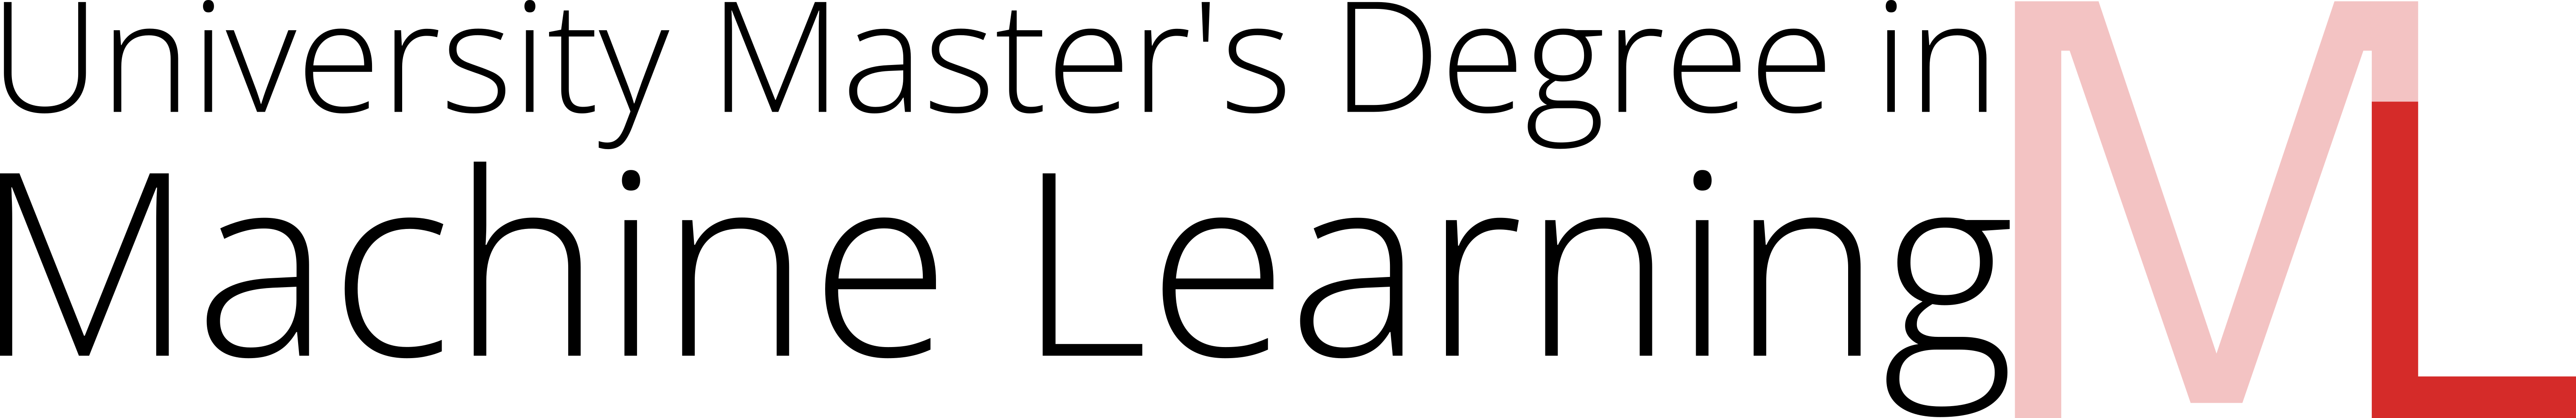

Once we have worked with nn.Conv2d for feature extraction, we will continue to increase the complexity of our model by adding more than one convolutional layer. In this practice, we will implement LeNet, which is considered one of the first standard convolutional neural networks and a classical model in computer visio

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as f
from matplotlib import pyplot as plt
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

## Stacking two convolutional layers

In this section, we will extend our previous work with the MLPWithConv model using the Fashion-MNIST dataset. The goal is to create a new model called MLPWith2Conv, which includes two convolutional layers with a pooling layer in between.

You should implement this new network architecture and then train it on the Fashion-MNIST dataset. Make sure to include a complete training loop. The details on the number of kernels, neurons and output dimensiones should be determined by yourself.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

# Fashion-MNIST
trainset = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
testset = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

trainloader = DataLoader(trainset, batch_size=64, shuffle=True)
testloader = DataLoader(testset, batch_size=1000, shuffle=False)

In [3]:
class MLPWith2Conv(nn.Module):
    def __init__(self, c1_out=16, c2_out=32, hidden_dim=128, num_classes=10):
        super().__init__()
        
        # Bloque 1: Conv1 -> ReLU -> MaxPool
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=c1_out, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Bloque 2: Conv2 -> ReLU -> MaxPool
        self.conv2 = nn.Conv2d(in_channels=c1_out, out_channels=c2_out, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Clasificador MLP (32 canales * 7 alto * 7 ancho = 1568)
        flatten_dim = c2_out * 7 * 7
        self.fc1 = nn.Linear(flatten_dim, hidden_dim)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # Bloque 1
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)
        
        # Bloque 2
        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)
        
        # Flatten
        x = x.view(x.size(0), -1)
        
        # MLP
        x = self.fc1(x)
        x = self.relu3(x)
        x = self.fc2(x)
        
        return x

In [4]:
# Detectar acelerador GPU/CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instanciar modelo, criterio de pérdida y optimizador
model = MLPWith2Conv(c1_out=16, c2_out=32, hidden_dim=128).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 5

for epoch in range(epochs):
    # ------------------ FASE DE ENTRENAMIENTO ------------------
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()
        
    epoch_loss = running_loss / len(trainset)
    train_acc = 100.0 * correct_train / total_train

    # ------------------ FASE DE EVALUACIÓN ------------------
    model.eval()
    correct_test = 0
    total_test = 0
    
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = outputs.max(1)
            total_test += labels.size(0)
            correct_test += predicted.eq(labels).sum().item()
            
    test_acc = 100.0 * correct_test / total_test
    
    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {epoch_loss:.4f} | "
          f"Train Acc: {train_acc:.2f}% | "
          f"Test Acc: {test_acc:.2f}%")

Epoch [1/5] | Train Loss: 0.5030 | Train Acc: 81.61% | Test Acc: 86.03%
Epoch [2/5] | Train Loss: 0.3258 | Train Acc: 88.17% | Test Acc: 88.36%
Epoch [3/5] | Train Loss: 0.2807 | Train Acc: 89.67% | Test Acc: 89.13%
Epoch [4/5] | Train Loss: 0.2526 | Train Acc: 90.75% | Test Acc: 89.76%
Epoch [5/5] | Train Loss: 0.2322 | Train Acc: 91.48% | Test Acc: 90.75%


Once you have implemented and trained your MLPWith2Conv model, it can be interesting to visualize the feature maps produced by the convolutional layers. The feature maps show what patterns or structures each convolutional layer is detecting in the input images.

You can use the following code snippet as a starting point to visualize the output of the first convolutional layer for a single input image.

In [5]:
import torchvision.utils as vutils

def show_grid(activations, nrow=6, title="Feature Maps"):

    act = activations.squeeze(0)  # [C,H,W]


    grid = vutils.make_grid(act.unsqueeze(1), nrow=nrow, normalize=True, padding=1)

    plt.figure(figsize=(12,6))
    plt.imshow(grid.permute(1, 2, 0).detach().numpy(), cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()





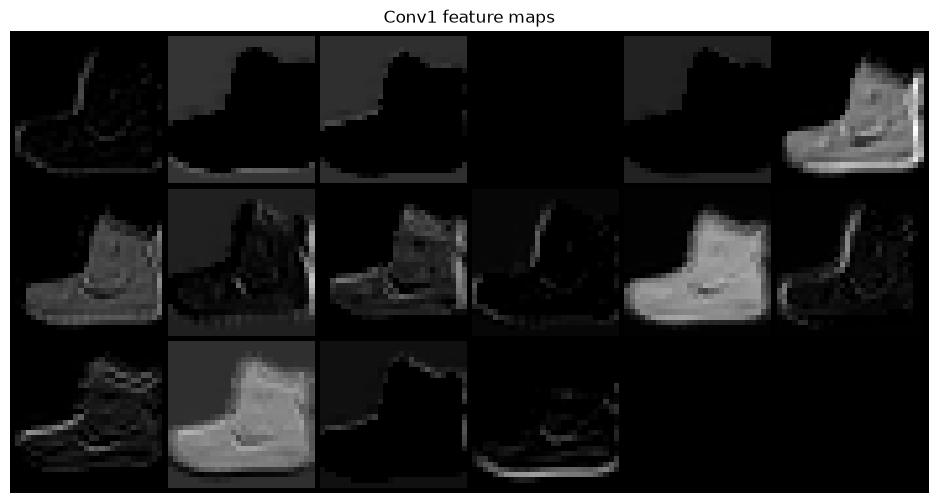

In [6]:
image, label = trainset[0]
image = image.unsqueeze(0)

model = model.to('cpu')


with torch.no_grad():
  act1 = torch.relu(model.conv1(image))


show_grid(act1, nrow=6, title="Conv1 feature maps")


## Classical LeNet

In this part of the practice, you will implement a classic version of LeNet, following the original architecture as closely as possible.

Before building the network, you need to resize the Fashion-MNIST images to 32x32, since the original LeNet was designed for this input size.

Your task is to implement LeNet in a single class. The architecture should include:

- Two convolutional layers with Tanh activations and average pooling.

- Fully connected layers at the end, following the original LeNet configuration.

- Flattening the output of the convolutional layers to feed into the fully connected layers.

After implementing the network, you should train it on the resized Fashion-MNIST images using a standard training loop, just like in the previous exercises.

In [7]:
class LeNetClassic(nn.Module):
    ##
    def __init__(self, num_classes=10):
        super().__init__()
        
        # 1. C1: Capa Convolucional (1 canal de entrada -> 6 mapas de características, filtro 5x5)
        self.c1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1, padding=0)
        self.act1 = nn.Tanh()
        
        # 2. S2: Capa de Submuestreo/Pooling (AvgPool 2x2 con stride 2)
        self.s2 = nn.AvgPool2d(kernel_size=2, stride=2)
        
        # 3. C3: Capa Convolucional (6 canales -> 16 mapas de características, filtro 5x5)
        self.c3 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1, padding=0)
        self.act2 = nn.Tanh()
        
        # 4. S4: Capa de Submuestreo/Pooling (AvgPool 2x2 con stride 2)
        self.s4 = nn.AvgPool2d(kernel_size=2, stride=2)
        
        # 5. C5: Convolución Densa / Capa Totalmente Conectada (16 * 5 * 5 = 400 aplanado -> 120)
        self.c5 = nn.Linear(16 * 5 * 5, 120)
        self.act3 = nn.Tanh()
        
        # 6. F6: Capa Totalmente Conectada (120 -> 84)
        self.f6 = nn.Linear(120, 84)
        self.act4 = nn.Tanh()
        
        # 7. Capa de Salida (84 -> num_classes)
        self.out = nn.Linear(84, num_classes)

    def forward(self, x):
        # x shape: (batch_size, 1, 32, 32)
        
        # C1 -> S2: (1, 32, 32) -> (6, 28, 28) -> (6, 14, 14)
        x = self.s2(self.act1(self.c1(x)))
        
        # C3 -> S4: (6, 14, 14) -> (16, 10, 10) -> (16, 5, 5)
        x = self.s4(self.act2(self.c3(x)))
        
        # Flattening: (batch_size, 16 * 5 * 5) = (batch_size, 400)
        x = x.view(x.size(0), -1)
        
        # Capas Densas (FC)
        x = self.act3(self.c5(x))
        x = self.act4(self.f6(x))
        x = self.out(x)
        
        return x

In [8]:
transform = transforms.Compose([
    transforms.Resize((32,32)),
    transforms.ToTensor()
])

# Fashion-MNIST
trainset = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
testset = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

trainloader = DataLoader(trainset, batch_size=64, shuffle=True)
testloader = DataLoader(testset, batch_size=1000, shuffle=False)

In [9]:
import torch.optim as optim
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Instanciar el modelo LeNetClassic, la función de pérdida y el optimizador
model = LeNetClassic(num_classes=10).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 3. Bucle de Entrenamiento y Evaluación
epochs = 5

for epoch in range(epochs):
    # FASE DE ENTRENAMIENTO
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()
        
    epoch_loss = running_loss / len(trainset)
    train_acc = 100.0 * correct_train / total_train

    # FASE DE EVALUACIÓN
    model.eval()
    correct_test = 0
    total_test = 0
    
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = outputs.max(1)
            total_test += labels.size(0)
            correct_test += predicted.eq(labels).sum().item()
            
    test_acc = 100.0 * correct_test / total_test
    
    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {epoch_loss:.4f} | "
          f"Train Acc: {train_acc:.2f}% | "
          f"Test Acc: {test_acc:.2f}%")

Epoch [1/5] | Train Loss: 0.6259 | Train Acc: 77.00% | Test Acc: 81.66%
Epoch [2/5] | Train Loss: 0.4206 | Train Acc: 84.46% | Test Acc: 85.10%
Epoch [3/5] | Train Loss: 0.3626 | Train Acc: 86.63% | Test Acc: 86.21%
Epoch [4/5] | Train Loss: 0.3326 | Train Acc: 87.89% | Test Acc: 86.35%
Epoch [5/5] | Train Loss: 0.3125 | Train Acc: 88.40% | Test Acc: 87.44%


## Modern LeNet

In this section, you have to introduce improvements to a modern version of LeNet. The goal is to adapt the classic architecture to current best practices while maintaining the general structure.

Some suggested improvements include:

- Using ReLU activations instead of Tanh.

- Replacing average pooling with max pooling.

- Introducing regularization techniques, for example, Dropout in the fully connected layers.

You should implement your modern LeNet variant, train it on the Fashion-MNIST dataset, and then evaluate and compare the performance with the classic LeNet. Consider aspects such as accuracy, training speed, and robustness.


In [10]:
class LeNetModern(nn.Module):
    def __init__(self, num_classes=10, dropout_rate=0.5):
        super().__init__()
        
        # 1. C1 + S2 (Conv -> ReLU -> MaxPool)
        self.c1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1, padding=0)
        self.act1 = nn.ReLU()
        self.s2 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # 2. C3 + S4 (Conv -> ReLU -> MaxPool)
        self.c3 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1, padding=0)
        self.act2 = nn.ReLU()
        self.s4 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # 3. Clasificador Denser con Dropout
        # Para entrada 32x32: 16 canales * 5 alto * 5 ancho = 400
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.act3 = nn.ReLU()
        self.dropout1 = nn.Dropout(p=dropout_rate)
        
        self.fc2 = nn.Linear(120, 84)
        self.act4 = nn.ReLU()
        self.dropout2 = nn.Dropout(p=dropout_rate)
        
        self.out = nn.Linear(84, num_classes)

    def forward(self, x):
        # Bloque 1: (1, 32, 32) -> (6, 28, 28) -> (6, 14, 14)
        x = self.s2(self.act1(self.c1(x)))
        
        # Bloque 2: (6, 14, 14) -> (16, 10, 10) -> (16, 5, 5)
        x = self.s4(self.act2(self.c3(x)))
        
        # Flatten
        x = x.view(x.size(0), -1)
        
        # Capas Densas con Dropout
        x = self.dropout1(self.act3(self.fc1(x)))
        x = self.dropout2(self.act4(self.fc2(x)))
        x = self.out(x)
        
        return x

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instanciar LeNetModern
model_modern = LeNetModern(num_classes=10, dropout_rate=0.3).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_modern.parameters(), lr=0.001)

epochs = 5

print("Entrenando LeNetModern...")
for epoch in range(epochs):
    # FASE DE ENTRENAMIENTO
    model_modern.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model_modern(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()
        
    epoch_loss = running_loss / len(trainset)
    train_acc = 100.0 * correct_train / total_train

    # FASE DE EVALUACIÓN
    model_modern.eval()
    correct_test = 0
    total_test = 0
    
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_modern(images)
            _, predicted = outputs.max(1)
            total_test += labels.size(0)
            correct_test += predicted.eq(labels).sum().item()
            
    test_acc = 100.0 * correct_test / total_test
    
    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {epoch_loss:.4f} | "
          f"Train Acc: {train_acc:.2f}% | "
          f"Test Acc: {test_acc:.2f}%")

Entrenando LeNetModern...
Epoch [1/5] | Train Loss: 0.7707 | Train Acc: 70.84% | Test Acc: 79.75%
Epoch [2/5] | Train Loss: 0.5213 | Train Acc: 80.73% | Test Acc: 83.15%
Epoch [3/5] | Train Loss: 0.4549 | Train Acc: 83.49% | Test Acc: 84.70%
Epoch [4/5] | Train Loss: 0.4095 | Train Acc: 85.30% | Test Acc: 86.22%
Epoch [5/5] | Train Loss: 0.3791 | Train Acc: 86.15% | Test Acc: 86.80%


## Dogs vs. Cats Classification with a Custom CNN

For the final part of the practice, you will work again with the **cats and dogs dataset** that we used on the first day dedicated to CNNs. Recall that the images were previously resized to **64x64** in the dataset.

Your task is to **implement a convolutional neural network** with **two convolutional layers** to classify dogs and cats. You are free to **design the network** in the way that you consider most effective.

As you experiment, consider the following questions:

* Would adding a **third convolutional layer** improve performance?
* How does the **input image size** affect the results?
* Is it easier to work with **color images** now compared to grayscale?
* What other design choices might help improve the network’s performance?

Train your network, evaluate its accuracy, and **analyze the impact of different architectural decisions**.



In [12]:
import torch
import torch.nn as nn

class CustomCNN2Conv(nn.Module):
    def __init__(self, num_classes=2, dropout_rate=0.3):
        super().__init__()
        
        # Bloque Convolucional 1
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Bloque Convolucional 2
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Clasificador MLP (64 canales * 16 * 16 = 16384)
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(p=dropout_rate)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        # Bloque 1: (3, 64, 64) -> (32, 32, 32)
        x = self.pool1(self.relu1(self.bn1(self.conv1(x))))
        
        # Bloque 2: (32, 32, 32) -> (64, 16, 16)
        x = self.pool2(self.relu2(self.bn2(self.conv2(x))))
        
        # Flatten
        x = x.view(x.size(0), -1)
        
        # MLP
        x = self.dropout(self.relu3(self.fc1(x)))
        x = self.fc2(x)
        
        return x

In [13]:
class CustomCNN3Conv(nn.Module):
    def __init__(self, num_classes=2, dropout_rate=0.3):
        super().__init__()
        
        # Bloque 1: (3, 64, 64) -> (32, 32, 32)
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(2, 2)
        
        # Bloque 2: (32, 32, 32) -> (64, 16, 16)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(2, 2)
        
        # Bloque 3: (64, 16, 16) -> (128, 8, 8)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(2, 2)
        
        self.relu = nn.ReLU()
        
        # Clasificador MLP (128 canales * 8 * 8 = 8192)
        self.fc1 = nn.Linear(128 * 8 * 8, 128)
        self.dropout = nn.Dropout(p=dropout_rate)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool1(self.relu(self.bn1(self.conv1(x))))
        x = self.pool2(self.relu(self.bn2(self.conv2(x))))
        x = self.pool3(self.relu(self.bn3(self.conv3(x))))
        
        x = x.view(x.size(0), -1)
        
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        
        return x

In [14]:
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Transformaciones para entrenamiento (incluye data augmentation para evitar sobreajuste)
train_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Cargar datasets (ajustar la ruta según la carpeta local)
train_dataset = datasets.ImageFolder(root='cat_dog_small/train', transform=train_transforms)
test_dataset = datasets.ImageFolder(root='cat_dog_small/test', transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Configuración del entrenamiento
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CustomCNN2Conv(num_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()
        
    epoch_loss = running_loss / len(train_dataset)
    train_acc = 100.0 * correct_train / total_train

    # Evaluación
    model.eval()
    correct_test = 0
    total_test = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = outputs.max(1)
            total_test += labels.size(0)
            correct_test += predicted.eq(labels).sum().item()
            
    test_acc = 100.0 * correct_test / total_test
    print(f"Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

Epoch [1/10] | Loss: 1.3374 | Train Acc: 53.40% | Test Acc: 54.50%
Epoch [2/10] | Loss: 0.6779 | Train Acc: 57.50% | Test Acc: 65.00%
Epoch [3/10] | Loss: 0.6460 | Train Acc: 62.00% | Test Acc: 71.50%
Epoch [4/10] | Loss: 0.6176 | Train Acc: 66.40% | Test Acc: 70.50%
Epoch [5/10] | Loss: 0.6007 | Train Acc: 66.40% | Test Acc: 73.50%
Epoch [6/10] | Loss: 0.5892 | Train Acc: 69.80% | Test Acc: 73.50%
Epoch [7/10] | Loss: 0.5869 | Train Acc: 68.90% | Test Acc: 73.50%
Epoch [8/10] | Loss: 0.5874 | Train Acc: 68.10% | Test Acc: 74.00%
Epoch [9/10] | Loss: 0.5686 | Train Acc: 70.20% | Test Acc: 72.50%
Epoch [10/10] | Loss: 0.5608 | Train Acc: 72.10% | Test Acc: 71.50%
